# EDA: MeteoSwiss, measured radiation and weather

**What the data is:** hourly measurements of automatic MeteoSwiss weather stations (SwissMetNet). We mainly use **global radiation** `gre000h0` (W/m², hourly mean), because it should explain solar generation. Also `sre000h0` (sunshine, minutes per hour) and `tre200h0` (air temperature, °C).

| | |
|---|---|
| Documentation | https://opendatadocs.meteoswiss.ch/a-data-groundbased/a1-automatic-weather-stations |
| Download | https://data.geo.admin.ch/browser/index.html#/collections/ch.meteoschweiz.ogd-smn (script: `download_data.py`) |
| Licence | CC BY 4.0, attribution "Source: MeteoSwiss" |
| Stations | Luzern (LUZ), Mosen (MOA), Schüpfheim (SPF), Egolzwil (EGO) in Canton Lucerne, plus Pilatus (PIL, 2,105 m, usually above the fog) |
| Files | `data/ogd-smn_<station>_h_*.csv`; large files are not versioned, `data/sample_luz_h_first_rows.txt` shows the format |
| One row | one station and one hour |
| Time span and resolution | hourly, files from 2010 to October 2026; we use 2019–2025 (same period as the target) |
| Time zone | delivered in UTC; **we work in Central European Time without clock changes (fixed CET = UTC+1) throughout the project** |

**How this notebook works:** every section starts with a **question**, then the code, a chart where useful, and a note **Finding → Consequence**.
Same structure as the Energy-Charts notebook: *Step 1* validity (Q1–Q9), *Step 2* patterns and suitability (Q10–Q13). *Step 3*, the overlay with solar generation, follows in the combined notebook.
*Prepared with AI assistance (Claude); findings to be questioned and checked by us.*

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data")
FIG = Path("../../figures/eda")
FIG.mkdir(parents=True, exist_ok=True)
TZ = "Etc/GMT-1"   # fixed CET = UTC+1, no clock changes (the minus sign is correct for this name)
STATIONS = {"LUZ": "Luzern", "MOA": "Mosen", "SPF": "Schüpfheim", "EGO": "Egolzwil", "PIL": "Pilatus"}
LUCERNE = ["LUZ", "MOA", "SPF", "EGO"]
pd.set_option("display.max_columns", None)   # show all columns side by side
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"


def save(fig, name):
    fig.savefig(FIG / f"meteoswiss_{name}.png", dpi=160, bbox_inches="tight")

# Step 1: Is the data valid?

## Q1: What does one raw file look like?

In [2]:
print((DATA / "sample_luz_h_first_rows.txt").read_text(encoding="cp1252")[:420])
parameters = pd.read_csv(DATA / "ogd-smn_meta_parameters.csv", sep=";", encoding="cp1252").set_index("parameter_shortname")
parameters.loc[["gre000h0", "sre000h0", "tre200h0"], ["parameter_description_en", "parameter_unit"]]

station_abbr;reference_timestamp;tre200h0;tre200hn;tre200hx;tre005h0;tre005hn;ure200h0;pva200h0;tde200h0;prestah0;pp0qffh0;pp0qnhh0;ppz700h0;ppz850h0;fkl010h1;dkl010h0;fkl010h0;fu3010h0;fu3010h1;fkl010h3;fu3010h3;wcc006h0;fve010h0;rre150h0;htoauths;gre000h0;oli000h0;olo000h0;osr000h0;ods000h0;sre000h0;erefaoh0;tso005hs;tso010hs;tso020hs
LUZ;01.01.2026 00:00;-5.5;-5.7;-5.3;-9.1;-9.3;89.6;3.6;-6.9;967.3;1024.8;1021.2;;


,parameter_description_en,parameter_unit
parameter_shortname,,
gre000h0,Global radiation; hourly mean,W/m²
sre000h0,Sunshine duration; hourly total,min
tre200h0,Air temperature 2 m above ground; hourly mean,°C


> **Finding:** one CSV per station and period, separated by `;`, with cryptic column names explained in the metadata file. Time stamps look like `01.01.2020 00:00` and are in UTC.
> **Consequence:** read with `sep=";"` and the exact date format, convert to CET, and look up each column name in the metadata.

## Q2: Load the stations into pandas. Which columns and data types do we have?

In [3]:
def load_station(abbr):
    files = sorted(DATA.glob(f"ogd-smn_{abbr.lower()}_h_*.csv"))
    d = pd.concat(pd.read_csv(f, sep=";", encoding="cp1252") for f in files)
    d["time_cet"] = pd.to_datetime(d["reference_timestamp"], format="%d.%m.%Y %H:%M", utc=True).dt.tz_convert(TZ)
    print(f"{abbr}: {len(d)} rows, duplicated time stamps: {d['time_cet'].duplicated().sum()}")
    return d.drop_duplicates("time_cet", keep="last").set_index("time_cet").sort_index()

met = {a: load_station(a) for a in STATIONS}
met["LUZ"].head()

LUZ: 147168 rows, duplicated time stamps: 0


MOA: 146988 rows, duplicated time stamps: 0


SPF: 146467 rows, duplicated time stamps: 0


EGO: 146468 rows, duplicated time stamps: 0


PIL: 146764 rows, duplicated time stamps: 0


,station_abbr,reference_timestamp,tre200h0,tre200hn,tre200hx,tre005h0,tre005hn,ure200h0,pva200h0,tde200h0,prestah0,pp0qffh0,pp0qnhh0,ppz700h0,ppz850h0,fkl010h1,dkl010h0,fkl010h0,fu3010h0,fu3010h1,fkl010h3,fu3010h3,wcc006h0,fve010h0,rre150h0,htoauths,gre000h0,oli000h0,olo000h0,osr000h0,ods000h0,sre000h0,erefaoh0,tso005hs,tso010hs,tso020hs
time_cet,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2010-01-01 01:00:00+01:00,LUZ,01.01.2010 00:00,2.1,1.4,2.7,-1.8,-2.4,97.7,7.0,1.8,939.1,993.3,991.7,NaN,NaN,1.8,256.0,0.5,1.8,6.5,1.7,6.1,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
2010-01-01 02:00:00+01:00,LUZ,01.01.2010 01:00,2.6,2.2,3.1,-0.4,-0.7,95.9,7.1,2.0,938.9,992.9,991.4,NaN,NaN,1.6,207.0,0.7,2.5,5.8,1.6,5.8,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
2010-01-01 03:00:00+01:00,LUZ,01.01.2010 02:00,2.7,2.2,3.1,0.2,-0.1,96.2,7.1,2.1,938.5,992.5,991.1,NaN,NaN,1.1,207.0,0.5,1.8,4.0,1.0,3.6,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
2010-01-01 04:00:00+01:00,LUZ,01.01.2010 03:00,2.6,1.9,2.9,-0.3,-0.9,95.7,7.0,2.0,937.9,991.9,990.4,NaN,NaN,1.9,194.0,0.9,3.2,6.8,1.8,6.5,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
2010-01-01 05:00:00+01:00,LUZ,01.01.2010 04:00,1.7,1.3,2.3,-1.8,-2.2,96.7,6.7,1.2,937.4,991.6,990.0,NaN,NaN,2.5,193.0,1.0,3.6,9.0,2.4,8.6,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN


In [4]:
met["LUZ"].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 147168 entries, 2010-01-01 01:00:00+01:00 to 2026-10-16 00:00:00+01:00
Data columns (total 36 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   station_abbr         147168 non-null  str    
 1   reference_timestamp  147168 non-null  str    
 2   tre200h0             147144 non-null  float64
 3   tre200hn             147143 non-null  float64
 4   tre200hx             147143 non-null  float64
 5   tre005h0             147009 non-null  float64
 6   tre005hn             146966 non-null  float64
 7   ure200h0             147144 non-null  float64
 8   pva200h0             147144 non-null  float64
 9   tde200h0             147144 non-null  float64
 10  prestah0             147144 non-null  float64
 11  pp0qffh0             147144 non-null  float64
 12  pp0qnhh0             147144 non-null  float64
 13  ppz700h0             0 non-null       float64
 14  ppz850h0             0 non-null  

In [5]:
met["LUZ"][["gre000h0", "sre000h0", "tre200h0"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
gre000h0,147086.0,137.6,226.3,0.0,0.0,5.0,185.0,1104.0
sre000h0,146946.0,11.5,21.5,0.0,0.0,0.0,8.0,60.0
tre200h0,147144.0,10.8,8.0,-13.7,4.4,10.6,16.7,36.1


> **Finding:** 36 columns per station, all numeric except the station name and the time stamp text. The `historical` and `recent` files do not overlap, so there are no duplicates.
> **Consequence:** keep only the columns we need. From here on we compare the radiation of the five stations for 2019–2025.

## Q3: Is every hour present? Where are values missing, and why?

     time stamps missing  radiation empty  sunshine empty  temperature empty
LUZ                    0                0             111                  0
MOA                   65              167           17606                146
SPF                    0                0           61368                274
EGO                    0                0           61368                 48
PIL                    0                0             315                  0

Gaps at Mosen (start, hours):
                    start  hours
2024-03-20 04:00:00+01:00     55
2024-05-06 13:00:00+01:00     47
2025-08-09 16:00:00+01:00     65


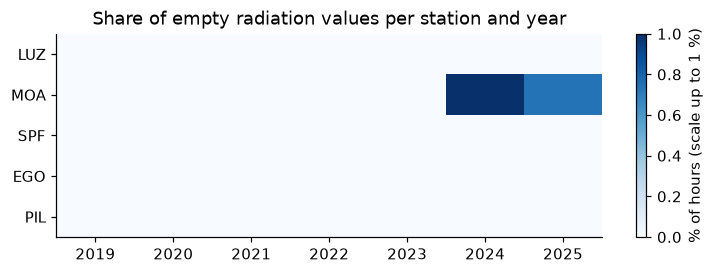

In [6]:
hours = pd.date_range("2019-01-01 00:00", "2025-12-31 23:00", freq="h", tz=TZ)
radiation = pd.DataFrame({a: met[a]["gre000h0"].reindex(hours) for a in STATIONS})

overview = pd.DataFrame({
    "time stamps missing": [len(hours.difference(met[a].index)) for a in STATIONS],
    "radiation empty": radiation.isna().sum().values,
    "sunshine empty": [met[a]["sre000h0"].reindex(hours).isna().sum() for a in STATIONS],
    "temperature empty": [met[a]["tre200h0"].reindex(hours).isna().sum() for a in STATIONS],
}, index=list(STATIONS))
print(overview.to_string())

gaps = radiation["MOA"].isna()
run = (gaps != gaps.shift()).cumsum()
print("\nGaps at Mosen (start, hours):")
print(pd.DataFrame({"start": gaps[gaps].index.to_series().groupby(run[gaps]).first(), "hours": gaps[gaps].groupby(run[gaps]).size()}).to_string(index=False))

missing = radiation.isna().groupby(radiation.index.year).mean() * 100
fig, ax = plt.subplots(figsize=(8, 2.4))
im = ax.imshow(missing.T, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(missing)), missing.index)
ax.set_yticks(range(5), missing.columns)
ax.set_title("Share of empty radiation values per station and year")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of hours (scale up to 1 %)")
save(fig, "missing_per_year")
plt.show()

> **Finding:** radiation is nearly complete: Luzern, Schüpfheim, Egolzwil and Pilatus have **no gaps** in 2019–2025. Only Mosen has three gaps of 55, 47 and 65 hours (0.27 % of its hours), probably outages; MeteoSwiss does not document the cause here. **Sunshine does not exist at all at Schüpfheim and Egolzwil**, and only partly at Mosen. Temperature has a few short gaps at Mosen, Schüpfheim and Egolzwil.
> **Consequence:** use radiation as the common variable, not sunshine. The gaps at Mosen are short and only at one station, so the average of the stations simply uses the others during those hours. No filling needed.

## Q4: Do the hourly values agree with MeteoSwiss' own daily values?

In [7]:
daily_files = [pd.read_csv(DATA / f, sep=";", encoding="cp1252") for f in ["ogd-smn_luz_d_historical.csv", "ogd-smn_luz_d_recent.csv"]]
official_daily = pd.concat(daily_files)
official_daily["day"] = pd.to_datetime(official_daily["reference_timestamp"], format="%d.%m.%Y %H:%M")
official_daily = official_daily.drop_duplicates("day", keep="last").set_index("day").sort_index()["gre000d0"].loc["2019":"2025"]

# daily mean from the hourly values, using the UTC day like the daily file
utc = met["LUZ"]["gre000h0"].tz_convert("UTC")
utc.index = utc.index - pd.Timedelta(hours=1)   # a stamp marks the end of the hour (see Q6)
from_hourly = utc.resample("D").mean().tz_localize(None).reindex(official_daily.index)
difference = (from_hourly - official_daily).abs()
print("Days compared:", difference.notna().sum(), "| mean difference:", round(difference.mean(), 2), "W/m² | largest:", round(difference.max(), 2), "W/m²")
print("Annual irradiation per station (kWh/m²; gaps at Mosen count as 0):")
(radiation.groupby(radiation.index.year).sum() / 1000).round(0)

Days compared: 2557 | mean difference: 0.25 W/m² | largest: 0.62 W/m²
Annual irradiation per station (kWh/m²; gaps at Mosen count as 0):


,LUZ,MOA,SPF,EGO,PIL
2019,1229.0,1295.0,1257.0,1317.0,1293.0
2020,1265.0,1332.0,1291.0,1352.0,1297.0
2021,1180.0,1234.0,1203.0,1252.0,1247.0
2022,1316.0,1384.0,1345.0,1404.0,1347.0
2023,1211.0,1240.0,1209.0,1297.0,1254.0
2024,1093.0,1112.0,1140.0,1176.0,1185.0
2025,1199.0,1236.0,1241.0,1298.0,1304.0


> **Finding:** the hourly values reproduce MeteoSwiss' own daily values for Luzern almost exactly (mean difference 0.25 W/m², at most 0.62 W/m²). Annual totals are similar across stations, with Luzern always the lowest of the four Lucerne stations except for Schüpfheim in 2023.
> **Consequence:** the hourly data can be trusted. One station alone would give a slightly biased level, which speaks for using several stations.

## Q5: Are there zeros that are really missing values?

In [8]:
midday = radiation[radiation.index.hour.isin([11, 12, 13, 14])]
print("Midday hours (11-14) with radiation = 0:")
print((midday == 0).sum().to_string())

daily = radiation.resample("D").sum(min_count=20) / 1000   # kWh/m² per day
print("\nDarkest days in Luzern, and the same days at the other stations (kWh/m²):")
daily.loc[daily["LUZ"].nsmallest(5).index].round(2)

Midday hours (11-14) with radiation = 0:
LUZ    0
MOA    0
SPF    0
EGO    0
PIL    0

Darkest days in Luzern, and the same days at the other stations (kWh/m²):


,LUZ,MOA,SPF,EGO,PIL
2025-12-24 00:00:00+01:00,0.08,0.11,0.02,0.16,0.46
2021-01-02 00:00:00+01:00,0.10,0.12,0.19,0.26,2.32
2020-12-02 00:00:00+01:00,0.10,0.36,0.12,0.44,1.81
2024-01-08 00:00:00+01:00,0.10,0.47,0.30,0.18,1.45
2019-12-02 00:00:00+01:00,0.11,0.35,0.22,0.42,1.29


Same period in two years side by side: two weeks in November. Do the Lucerne stations and Pilatus move together?

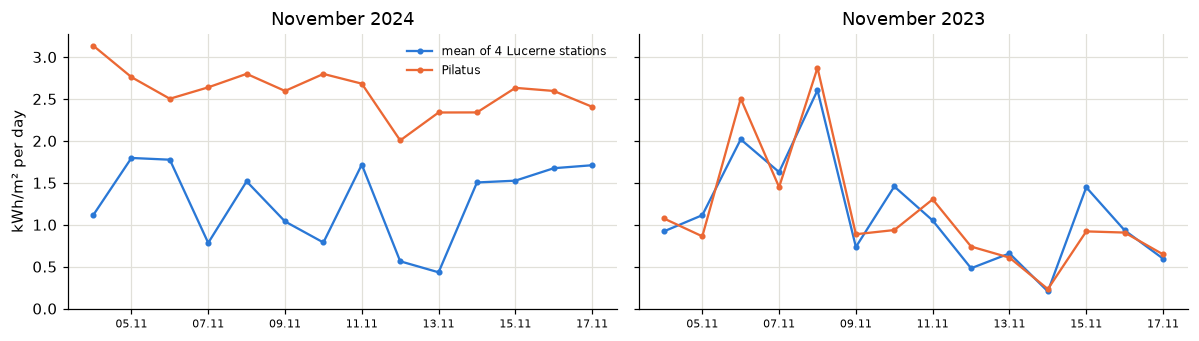

In [9]:
periods = [("2024-11-04", "2024-11-17", "November 2024"), ("2023-11-04", "2023-11-17", "November 2023")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (a, b, title) in zip(axes, periods):
    d = daily.loc[a:b]
    ax.plot(d.index, d[LUCERNE].mean(axis=1), color=BLUE, marker="o", markersize=3, label="mean of 4 Lucerne stations")
    ax.plot(d.index, d["PIL"], color=ORANGE, marker="o", markersize=3, label="Pilatus")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m", tz=TZ))
    ax.tick_params(axis="x", labelsize=7)
    ax.set_title(title)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("kWh/m² per day")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "november_2024_vs_2023")
plt.show()

> **Finding:** no station reports 0 at midday, so **there are no disguised gaps**. The darkest days are real: all Lucerne stations are dark at the same time, while Pilatus is often much brighter (e.g. 02.01.2021: 0.10 in Luzern, 2.32 kWh/m² on Pilatus). The charts show why: in November 2024 Pilatus stays bright while the Lucerne stations stay low, probably fog or low cloud; in the same two weeks of 2023 both move together.
> **Consequence:** keep the very low values; they are weather, not errors. Pilatus adds information about fog in winter.

## Q6: Time zone. What does a time stamp mean?

In [10]:
luz = radiation["LUZ"].dropna()
# Test: the radiation-weighted mean hour lies close to solar noon. In Lucerne (8.3° E) that is 12 - 8.3/15 = 11.45 UTC.
# If a stamp marks the start of the hour we expect about 10.95, if it marks the end about 11.95.
utc_hour = luz.index.tz_convert("UTC").hour
print("Radiation-weighted mean hour (UTC):", round((utc_hour * luz).sum() / luz.sum(), 2))

peak = pd.to_datetime(luz.groupby(luz.index.date).idxmax().values, utc=True).tz_convert(TZ)
print("Hour of the highest radiation in Luzern, median, in CET as delivered:", np.median(peak.hour))
per_day = luz.groupby(luz.index.date).size()
print("Days with fewer or more than 24 hours in CET:", (per_day.iloc[1:-1] != 24).sum())

# Align with Energy-Charts, which stamps the START of each hour
radiation.index = radiation.index - pd.Timedelta(hours=1)
radiation = radiation.loc["2019":"2025"]
print("Radiation is now stamped at the start of each hour.")

Radiation-weighted mean hour (UTC): 11.91
Hour of the highest radiation in Luzern, median, in CET as delivered: 13.0
Days with fewer or more than 24 hours in CET: 0
Radiation is now stamped at the start of each hour.


> **Finding:** the radiation-weighted mean hour is 11.91 UTC, which fits a stamp at the **end** of the hour (expected about 11.95, not 10.95). Energy-Charts stamps the *start* of the hour. In fixed CET every day has 24 hours.
> **Consequence:** convert to fixed CET and shift MeteoSwiss by **−1 h** (done above). Then the peak is at 12:00 all year, like the solar generation.

## Q7: Are there impossible values?

Negative radiation values: 0
Night hours (23-03) with radiation above 10 W/m²: 0
Highest radiation per station (W/m²): {'LUZ': 1069.0, 'MOA': 1036.0, 'SPF': 1092.0, 'EGO': 1040.0, 'PIL': 1157.0}
(for comparison: about 1,361 W/m² arrive at the top of the atmosphere)
Night hours (00-03): mean radiation (W/m²): {'LUZ': 0.01, 'MOA': 0.42, 'SPF': 0.0, 'EGO': 2.68, 'PIL': 0.0}
Night hours (00-03): share of exact zeros: {'LUZ': 0.99, 'MOA': 0.59, 'SPF': 1.0, 'EGO': 0.02, 'PIL': 1.0}
Egolzwil, mean night value per year (W/m²): {2019: 2.54, 2020: 2.52, 2021: 2.82, 2022: 3.01, 2023: 2.56, 2024: 2.59, 2025: 2.71}
Egolzwil, total in the night window 22:00-03:59, per year (kWh/m²): 5.8 = 0.4 % of its total
Sunshine per hour, maximum (minutes): 60.0
Temperature range (°C): {'LUZ': -8.2, 'MOA': -13.3, 'SPF': -15.4, 'EGO': -13.7, 'PIL': -15.2} to {'LUZ': 35.1, 'MOA': 35.5, 'SPF': 33.6, 'EGO': 34.9, 'PIL': 23.8}


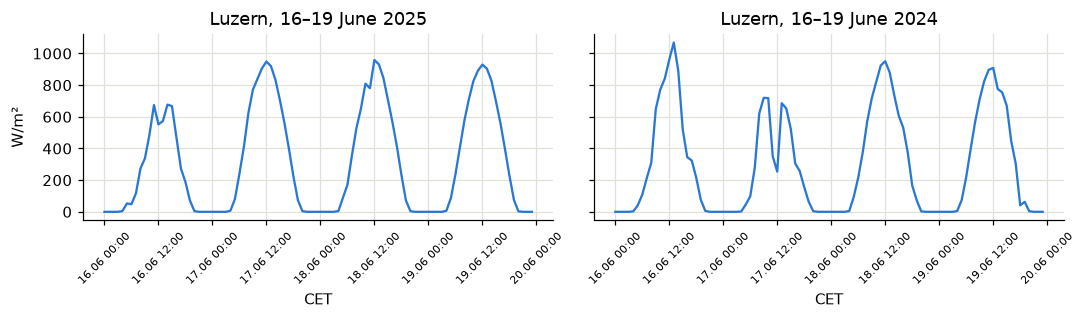

In [11]:
print("Negative radiation values:", (radiation < 0).sum().sum())
night = radiation[radiation.index.hour.isin([23, 0, 1, 2, 3])]
print("Night hours (23-03) with radiation above 10 W/m²:", (night > 10).sum().sum())
print("Highest radiation per station (W/m²):", radiation.max().to_dict())
print("(for comparison: about 1,361 W/m² arrive at the top of the atmosphere)")
sun = pd.DataFrame({a: met[a]["sre000h0"].reindex(hours) for a in STATIONS})
temp = pd.DataFrame({a: met[a]["tre200h0"].reindex(hours) for a in STATIONS})
night_hours = radiation[radiation.index.hour.isin([0, 1, 2, 3])]
print("Night hours (00-03): mean radiation (W/m²):", night_hours.mean().round(2).to_dict())
print("Night hours (00-03): share of exact zeros:", (night_hours == 0).mean().round(2).to_dict())
print("Egolzwil, mean night value per year (W/m²):", night_hours["EGO"].groupby(night_hours.index.year).mean().round(2).to_dict())
ego_night = radiation["EGO"][radiation.index.hour.isin([22, 23, 0, 1, 2, 3])]
print("Egolzwil, total in the night window 22:00-03:59, per year (kWh/m²):", round(ego_night.sum() / 1000 / 7, 1), "=", round(ego_night.sum() / radiation["EGO"].sum() * 100, 1), "% of its total")
print("Sunshine per hour, maximum (minutes):", sun.max().max())
print("Temperature range (°C):", temp.min().round(1).to_dict(), "to", temp.max().round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, year in zip(axes, [2025, 2024]):
    s = radiation["LUZ"].loc[f"{year}-06-16":f"{year}-06-19"]
    ax.plot(s.index, s.values, color=BLUE)
    ax.set_title(f"Luzern, 16–19 June {year}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M", tz=TZ))
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ax.set_xlabel("CET")
axes[0].set_ylabel("W/m²")
plt.tight_layout()
save(fig, "june_days")
plt.show()

> **Finding:** no negative values, no sunshine above 60 minutes per hour, plausible temperatures, and no night value above 10 W/m². The highest hourly radiation is 1,036–1,157 W/m², below the 1,361 W/m² at the top of the atmosphere. It is high for an hourly mean; the highest value in Luzern is the sharp peak on the first day of the right chart (16 June 2024). **Egolzwil almost never reads exactly 0 at night** (mean +2.68 W/m²), which looks like a small sensor offset; Mosen has a smaller one.
> **Consequence:** keep the high values, they are physically possible. Set the night hours (22:00–03:59) to 0, which removes about 6 kWh/m² (0.4 % of its total) per year at Egolzwil.
> **To question:** the offset is stable from year to year (2.5–3.0 W/m²), but is it also present during the day? We can only measure it at night; if it were there all day, it would add about 23 kWh/m² per year (about 2 %).

## Q8: Did a sensor get stuck or drift over time?

Longest flat stretch above 5 W/m² (hours): {'LUZ': 3, 'MOA': 2, 'SPF': 3, 'EGO': 2, 'PIL': 3}


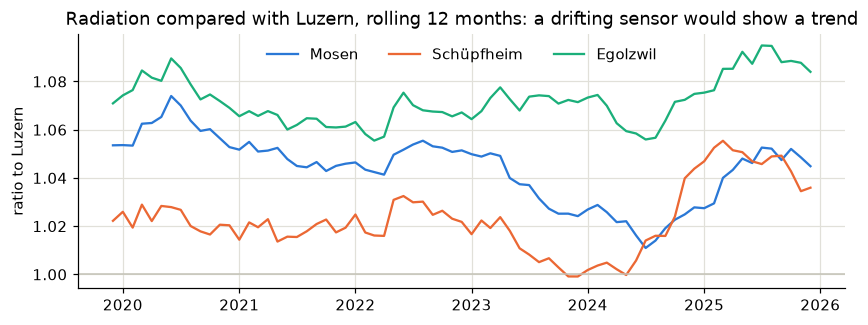

,LUZ,MOA,SPF,EGO,PIL
2019,1.0,1.054,1.022,1.071,1.052
2020,1.0,1.053,1.020,1.069,1.025
2021,1.0,1.046,1.019,1.061,1.057
2022,1.0,1.051,1.022,1.067,1.024
2023,1.0,1.024,0.999,1.071,1.036
2024,1.0,1.028,1.044,1.075,1.084
2025,1.0,1.045,1.036,1.084,1.088


In [12]:
def longest_flat(s):
    # longest stretch where the value stays exactly the same, during the day only
    s = s.dropna()
    run = (s != s.shift()).cumsum()
    return s[s > 5].groupby(run[s > 5]).size().max()

print("Longest flat stretch above 5 W/m² (hours):", {a: int(longest_flat(radiation[a])) for a in STATIONS})

common = radiation.dropna()   # only hours with values at all stations, so the gaps at Mosen do not count as 0
monthly_sum = common.resample("MS").sum().rolling(12).sum()   # energy-weighted: dark winter months count less
ratio = monthly_sum.div(monthly_sum["LUZ"], axis=0)
annual_ratio = common.groupby(common.index.year).sum().div(common["LUZ"].groupby(common.index.year).sum(), axis=0).round(3)
fig, ax = plt.subplots(figsize=(9, 3))
colors = {"MOA": BLUE, "SPF": ORANGE, "EGO": "#1baf7a"}
for a, c in colors.items():
    ax.plot(ratio.index, ratio[a], color=c, label=STATIONS[a])
ax.axhline(1, color=GREY, linewidth=1)
ax.set_ylabel("ratio to Luzern")
ax.set_title("Radiation compared with Luzern, rolling 12 months: a drifting sensor would show a trend")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y", tz=TZ))
ax.legend(frameon=False, ncols=3)
save(fig, "ratio_to_luzern")
plt.show()
annual_ratio

> **Finding:** **no stuck sensor:** the longest flat stretch during the day is 3 hours. Compared with Luzern each station keeps its own level, within a narrow band but not perfectly: Mosen and Schüpfheim fall by about 2–4 percentage points during 2023, and rise again afterwards (Schüpfheim from 2024, Mosen from late 2024). We cannot tell from this data whether that is the sensors or real weather differences.
> **Consequence:** treat about ±3 % as the uncertainty of a single station over time, on top of its fixed level difference. Averaging the stations reduces it. No correction.

## Q9: Do the columns fit together?

In [13]:
check = pd.DataFrame({"radiation": met["LUZ"]["gre000h0"], "sunshine": met["LUZ"]["sre000h0"]}).reindex(hours)
print("Hours with sunshine but no radiation:", ((check["sunshine"] > 0) & (check["radiation"] == 0)).sum())
print("Mean radiation by sunshine minutes per hour (W/m²):")
print(check.groupby(pd.cut(check["sunshine"], [-1, 0, 15, 30, 45, 60]), observed=True)["radiation"].mean().round(0).to_string())
print("\nDaily correlation between stations (Pearson r):")
daily.corr().round(2)

Hours with sunshine but no radiation: 0
Mean radiation by sunshine minutes per hour (W/m²):
sunshine
(-1, 0]      25.0
(0, 15]     205.0
(15, 30]    293.0
(30, 45]    376.0
(45, 60]    532.0

Daily correlation between stations (Pearson r):


,LUZ,MOA,SPF,EGO,PIL
LUZ,1.00,0.97,0.97,0.97,0.87
MOA,0.97,1.00,0.96,0.99,0.86
SPF,0.97,0.96,1.00,0.97,0.88
EGO,0.97,0.99,0.97,1.00,0.85
PIL,0.87,0.86,0.88,0.85,1.00


> **Finding:** the columns fit together (tested in Luzern): no hour has sunshine without radiation, and radiation rises with the sunshine minutes. The Lucerne stations correlate strongly with each other (Pearson r = 0.96–0.99, daily), Pilatus clearly less (0.85–0.88).
> **Consequence:** the four Lucerne stations describe the same weather but are not identical, so an average is reasonable. Pilatus is a different signal, which is why it can add information.

# Step 2: Does the data contain the patterns we need?

## Q10: What does the series look like over time, and how are the values distributed?

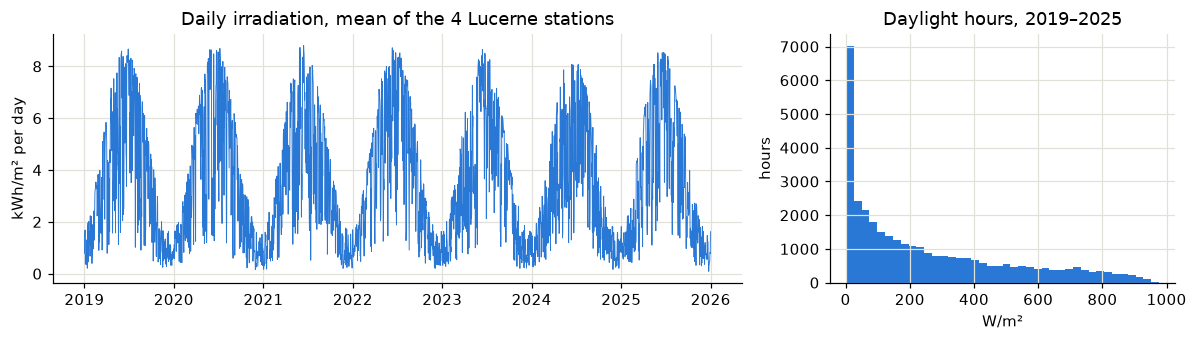

Hours below 5 W/m² (night and dusk): 50 %
Annual irradiation (kWh/m²): {2019: 1274.0, 2020: 1310.0, 2021: 1217.0, 2022: 1362.0, 2023: 1239.0, 2024: 1133.0, 2025: 1247.0}


In [14]:
lucerne_mean = radiation[LUCERNE].mean(axis=1)           # simple average of the four Lucerne stations
daily_mean = lucerne_mean.resample("D").sum(min_count=20) / 1000
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(daily_mean.index, daily_mean.values, color=BLUE, linewidth=0.6)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y", tz=TZ))
axes[0].set_ylabel("kWh/m² per day")
axes[0].set_title("Daily irradiation, mean of the 4 Lucerne stations")
axes[1].hist(lucerne_mean[lucerne_mean > 1], bins=40, color=BLUE)
axes[1].set_xlabel("W/m²")
axes[1].set_ylabel("hours")
axes[1].set_title("Daylight hours, 2019–2025")
plt.tight_layout()
save(fig, "series_and_distribution")
plt.show()
print(f"Hours below 5 W/m² (night and dusk): {(lucerne_mean < 5).mean() * 100:.0f} %")
print("Annual irradiation (kWh/m²):", (lucerne_mean.groupby(lucerne_mean.index.year).sum() / 1000).round(0).to_dict())

> **Finding:** unlike solar generation, radiation has **no growth**: the same yearly curve repeats, with 1,133 (2024) to 1,362 kWh/m² (2022) per year. Most daylight hours have low values; high values occur on clear days, mostly from March to September.
> **Consequence:** no normalisation needed. The best and the worst year differ by 20 % (2022 vs. 2024): real weather, so we need several years to learn from. For the overlay we use the **average of the four Lucerne stations**.

## Q11: Why is this dataset suitable for our goals?
Does it contain recurring patterns (daily, weekly, seasonal), and can it explain solar generation? The course guide suggests a heatmap ("mosaic plot").

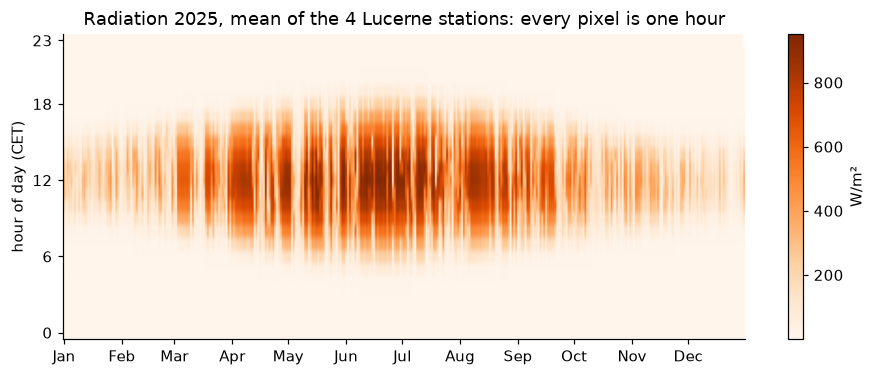

Difference between weekdays: 2.6 %
Days from October to February with more than twice as much radiation on Pilatus (and Pilatus at least 1.5 kWh/m²): 15 %
Difference to Luzern on days with values at all stations (%): {'LUZ': 0.0, 'MOA': 4.3, 'SPF': 2.3, 'EGO': 7.1}


In [15]:
s = lucerne_mean.loc["2025"]
mosaic = s.to_frame("W").assign(day=s.index.dayofyear, hour=s.index.hour).pivot_table(index="hour", columns="day", values="W")
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(mosaic, aspect="auto", origin="lower", cmap="Oranges", extent=[0.5, mosaic.shape[1] + 0.5, -0.5, 23.5])
ax.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335], ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks([0, 6, 12, 18, 23])
ax.set_ylabel("hour of day (CET)")
ax.set_title("Radiation 2025, mean of the 4 Lucerne stations: every pixel is one hour")
ax.grid(False)
fig.colorbar(im, ax=ax, label="W/m²")
save(fig, "mosaic_2025")
plt.show()

by_weekday = daily_mean.groupby(daily_mean.index.dayofweek).mean()
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Difference between weekdays:", round((by_weekday.max() / by_weekday.min() - 1) * 100, 1), "%")

# Fog: much brighter on Pilatus than in Lucerne, October to February
d = daily.copy()
winter = d[d.index.month.isin([10, 11, 12, 1, 2])]
fog = (winter["PIL"] > 2 * winter[LUCERNE].mean(axis=1)) & (winter["PIL"] >= 1.5)
print(f"Days from October to February with more than twice as much radiation on Pilatus (and Pilatus at least 1.5 kWh/m²): {fog.mean() * 100:.0f} %")
same_days = d[LUCERNE].dropna()
print("Difference to Luzern on days with values at all stations (%):", ((same_days.sum() / same_days["LUZ"].sum() - 1) * 100).round(1).to_dict())

> **Finding:**
> - The heatmap shows the same **daily and seasonal patterns** as the solar generation, including light stripes on cloudy days. That is what we need to explain the solar curve.
> - There is **no weekly pattern** (weekdays differ by less than 3 %), as expected for weather.
> - On about **15 % of the days** from October to February it is more than twice as bright on Pilatus as in Lucerne (with at least 1.5 kWh/m² on Pilatus): probably fog or low cloud over the plateau.
> - The stations differ in level: over the year Mosen +4.3 %, Schüpfheim +2.3 % and Egolzwil +7.1 % compared with Luzern.
>
> **Consequence:** suitable as the explanatory data for G2 and G3, **but only partly**: it covers Canton Lucerne, while the target is national, so the overlay shows how well Lucerne's weather represents Switzerland. The real test is Step 3.

## Q12: Leakage. Which values will not exist at prediction time?

In [16]:
same_day = daily_mean.corr(daily_mean.shift(1))
print("Daily irradiation vs. the day before (Pearson r):", round(same_day, 2))
season = daily_mean.groupby(daily_mean.index.dayofyear).transform("mean")
print("Same, after removing the seasonal average:", round((daily_mean - season).corr((daily_mean - season).shift(1)), 2))

Daily irradiation vs. the day before (Pearson r): 0.78
Same, after removing the seasonal average: 0.41


> **Finding:** all measured values only exist **after** the hour they describe, so they are not known when a forecast is made the day before. Yesterday's weather alone helps little: after removing the season, today correlates with yesterday at only r = 0.41.
> **Consequence:** use measured radiation to understand the relationship (G2) and to fit the model. For testing the day-ahead forecast (G3), use only archived weather **forecasts** (Open-Meteo, Flurin's notebook). Measured weather of the same day in the test would be leakage.

## Q13: Baseline. What would a very simple prediction of the radiation score?

In [17]:
test = lucerne_mean.loc["2025"]
train_mean = lucerne_mean.loc["2019":"2024"].mean()
baseline = pd.Series({
    "constant: mean of 2019-2024": (test - train_mean).abs().mean() / test.mean() * 100,
    "same hour of the previous day": (lucerne_mean.shift(24).loc["2025"] - test).abs().mean() / test.mean() * 100,
}).round(1)
baseline.rename("MAE in % of the mean, test year 2025").to_frame()

,"MAE in % of the mean, test year 2025"
constant: mean of 2019-2024,122.3
same hour of the previous day,35.1


> **Finding:** a constant prediction is off by about **122 %** of the mean, "same hour as yesterday" by about **35 %**. Radiation is therefore harder to predict naively than the national solar generation (about 28 %, Energy-Charts notebook, Q13), probably because one region varies more than all of Switzerland.
> **Consequence:** these are yardsticks for the weather forecasts: a useful radiation forecast must clearly beat 35 %. We compare this with the Open-Meteo forecasts in the combined notebook.

# Summary

## Decision log

| # | Issue | Error or characteristic? | Decision | Affected |
|---|---|---|---|---|
| Q3 | Mosen: three gaps in radiation | outage (cause not documented) | not filled; average uses the other stations | 167 hours |
| Q3 | No sunshine at Schüpfheim and Egolzwil | characteristic | use radiation as the common variable | 2 stations |
| Q6 | Time stamps mark the end of the hour, in UTC | characteristic | convert to fixed CET, shift by −1 h | all |
| Q5 | Very dark days | characteristic (real weather, fog) | keep | – |
| Q7 | Egolzwil (and slightly Mosen) above 0 at night | sensor offset | set night hours to 0 | Egolzwil: 0.4 % of its annual total |
| Q7 | Very high hourly values up to 1,157 W/m² | characteristic (physically possible) | keep | – |
| Q8 | Stations differ from Luzern by a few % over time | unknown | no correction; average the stations | ±3 % |
| Q12 | Measured weather not known a day ahead | leakage risk | test only with weather forecasts | – |

## Is the data suitable? (Insights)

**Yes for the weather side, with one limit.** It is complete, consistent and shows the patterns we need. The limit: it describes Canton Lucerne, while the solar target is national. How well that fits is the question of Step 3.

## Open questions (to discuss)

1. **Which average?** Simple mean of the four Lucerne stations for now, or weighted by installed PV capacity (needs the SFOE register, Flurin's notebook)?
2. **Pilatus:** use it as an extra input for fog days, or only to explain them?
3. **Egolzwil offset:** is setting the night hours to 0 enough, or should we subtract the offset all day?

## Next steps (Step 3 of the guide)

- Combined notebook: **average radiation overlaid with the reported solar GW** (matplotlib), with all sources in fixed CET.
- There: check the suspicious days of the Energy-Charts notebook against the radiation.